
fitted = a * t_dot_sample + offset

t_callback = a * t_dot_sample + b_true + w + d
where

a = Relative DOT-to-gateway clock rate
b_true = Actual clock offset
w =	Waiting time for a BLE connection event
d = Other delays: buffering, transmission and callback processing

Clock-mesh currently only observes the sensor timestamp and the gateway callback timestamp
consequently the b value include w and d and b_true

If we can estimate the waiting time (we have the ideal times from the derived 9 sample model
we can remove it and leave only the d component (the delay from buffers and processing)

next step is to calculate the nine average residual values from Plot A and compare them against the theoretical nine-phase sequence


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import math

path = "../output-files/clock-mesh/20261022T083342.825648Z_4effaa7f/observations.csv"
df = pd.read_csv(path)

# Isolate one DOT
dot = df[
    (df["address"] == "D4:22:CD:07:B4:5E")
].copy()

dot = dot.sort_values("unwrapped_dot_timestamp_us")

# First calibration source timestamp.
dot_t0 = dot["unwrapped_dot_timestamp_us"].iloc[0]

# X: elapsed DOT time in seconds.
dot["dot_elapsed_s"] = (
    dot["unwrapped_dot_timestamp_us"] - dot_t0
) / 1_000_000

In [5]:
plot_data = dot.dropna(
    subset=["reference_time_ns", "mapped_timestamp_ns"]
).copy()

plot_data = plot_data[
    plot_data["dot_elapsed_s"].between(2.2, 4.8)
].copy()

# Observed callback minus ClockMesh fitted time (ms).
plot_data["residual_ms"] = (
    plot_data["reference_time_ns"]
    - plot_data["mapped_timestamp_ns"]
) / 1_000_000

# Recover the original DOT sample index.
# This preserves phase even if a sample is missing.
plot_data["sample_index"] = np.rint(
    (plot_data["unwrapped_dot_timestamp_us"] - dot_t0)
    / (1_000_000 / 60)
).astype(int)

# Position within the nine-sample cycle.
plot_data["phase9"] = plot_data["sample_index"] % 9

print(
    plot_data[
        ["dot_elapsed_s", "sample_index", "phase9", "residual_ms"]
    ].head(20).round(3)
)

     dot_elapsed_s  sample_index  phase9  residual_ms
256          2.200           132       6       -3.267
259          2.217           133       7        8.988
260          2.233           134       8       -7.013
263          2.250           135       0        5.625
264          2.267           136       1      -10.344
267          2.283           137       2        2.295
268          2.300           138       3      -13.707
270          2.317           139       4       -0.652
273          2.333           140       5       12.275
274          2.350           141       6       -3.727
277          2.367           142       7        8.912
278          2.383           143       8       -7.057
281          2.400           144       0        5.581
282          2.417           145       1      -10.420
285          2.433           146       2        2.218
286          2.450           147       3      -13.751
288          2.467           148       4       -1.112
291          2.483          

In [6]:
phase_summary = (
    plot_data.groupby("phase9")["residual_ms"]
    .agg(mean="mean", std="std", count="count")
    .reindex(range(9))
)

print(phase_summary.round(3))

          mean    std  count
phase9                      
0        5.155  0.302     17
1      -10.833  0.304     17
2        1.805  0.304     17
3      -14.181  0.304     17
4        0.261  7.288     17
5       13.600  7.258     17
6       -2.444  7.043     18
7        8.543  0.437     18
8       -7.443  0.433     18


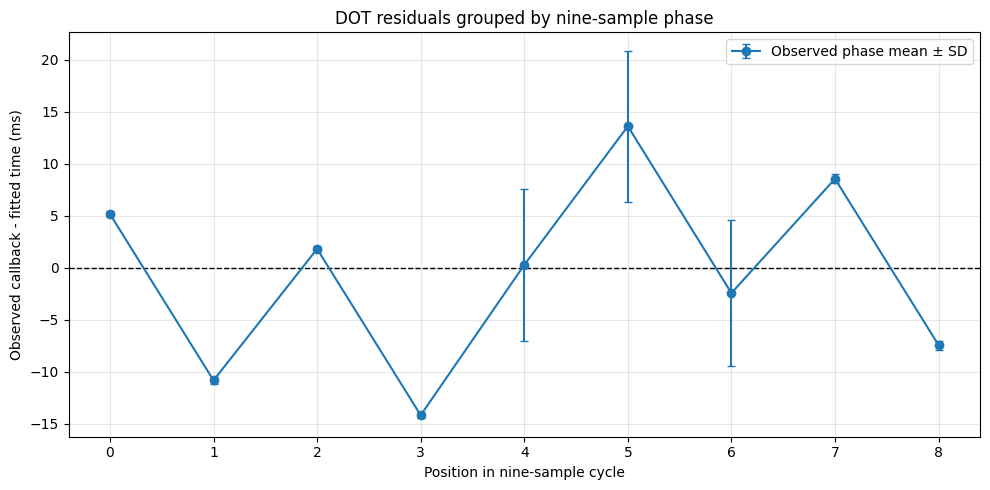

In [7]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.errorbar(
    phase_summary.index,
    phase_summary["mean"],
    yerr=phase_summary["std"],
    fmt="o-",
    capsize=3,
    label="Observed phase mean ± SD"
)

ax.axhline(0, color="black", linestyle="--", linewidth=1)

ax.set_xlabel("Position in nine-sample cycle")
ax.set_ylabel("Observed callback - fitted time (ms)")
ax.set_title("DOT residuals grouped by nine-sample phase")
ax.set_xticks(range(9))
ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

In [8]:
Ts = 1000 / 60  # DOT sample period, ms
Tc = 30.0       # BLE connection interval, ms

phases = np.arange(9)

# Try possible starting phases between 0 and 30 ms.
phi_values = np.linspace(0, Tc, 3000, endpoint=False)

# Theoretical waiting time for each phase.
waiting = (
    phi_values[:, None] - phases[None, :] * Ts
) % Tc

# Remove the mean waiting time from each candidate pattern.
theory = waiting - waiting.mean(axis=1, keepdims=True)

# Center the observed residuals for shape comparison.
observed = phase_summary["mean"].to_numpy()
observed_centered = observed - np.nanmean(observed)

# Find the theoretical phase with the smallest squared error.
valid = np.isfinite(observed_centered)

mse = np.mean(
    (theory[:, valid] - observed_centered[valid]) ** 2,
    axis=1
)

best_index = np.argmin(mse)
best_phi = phi_values[best_index]
best_theory = theory[best_index]

print(f"Best starting phase: {best_phi:.3f} ms")
print(f"Pattern RMSE: {np.sqrt(mse[best_index]):.3f} ms")

Best starting phase: 20.180 ms
Pattern RMSE: 0.835 ms


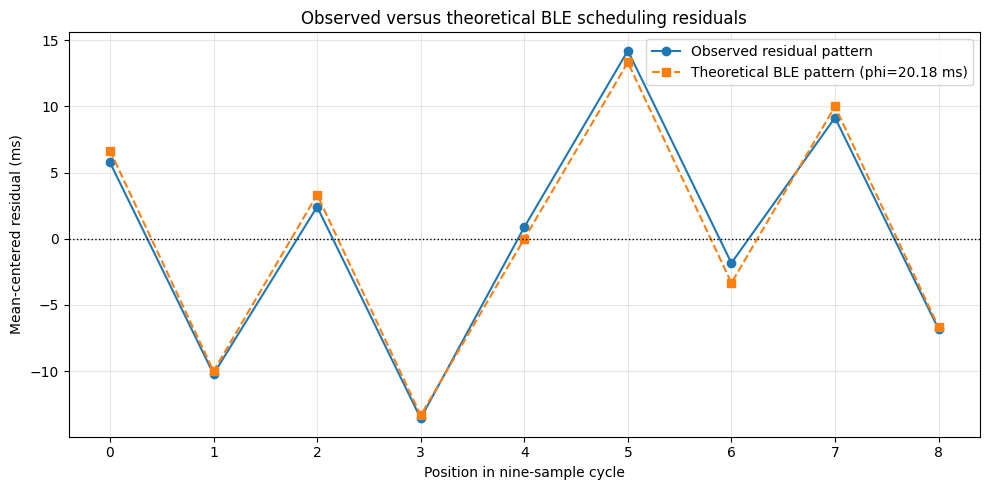

In [9]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    phases,
    observed_centered,
    "o-",
    label="Observed residual pattern"
)

ax.plot(
    phases,
    best_theory,
    "s--",
    label=f"Theoretical BLE pattern (phi={best_phi:.2f} ms)"
)

ax.axhline(0, color="black", linestyle=":", linewidth=1)

ax.set_xlabel("Position in nine-sample cycle")
ax.set_ylabel("Mean-centered residual (ms)")
ax.set_title("Observed versus theoretical BLE scheduling residuals")
ax.set_xticks(phases)
ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

In [10]:
check = plot_data.copy()

# Identify each nine-sample cycle.
check["cycle9"] = check["sample_index"] // 9

# Find the typical residual for each phase.
check["phase_median_ms"] = (
    check.groupby("phase9")["residual_ms"]
    .transform("median")
)

# Difference from the typical value for that phase.
check["deviation_ms"] = (
    check["residual_ms"] - check["phase_median_ms"]
)

# Identify observations displaced by more than 10 ms.
outliers = check[
    check["deviation_ms"].abs() > 10
]

print(
    outliers[
        [
            "cycle9",
            "sample_index",
            "phase9",
            "dot_elapsed_s",
            "residual_ms",
            "deviation_ms"
        ]
    ].round(3).to_string(index=False)
)

 cycle9  sample_index  phase9  dot_elapsed_s  residual_ms  deviation_ms
     22           202       4          3.367       28.510        30.028
     24           221       5          3.683       41.732        29.819
     24           222       6          3.700       25.731        29.781


In [11]:
inspect = check.sort_values("sample_index").copy()

inspect["callback_interval_ms"] = (
    inspect["reference_time_ns"].diff() / 1_000_000
)

inspect["residual_step_ms"] = (
    inspect["residual_ms"].diff()
)

columns = [
    "sample_index",
    "phase9",
    "dot_elapsed_s",
    "callback_interval_ms",
    "residual_ms",
    "deviation_ms",
    "residual_step_ms",
]

# First delayed observation
print("AROUND SAMPLE 202")
print(
    inspect.loc[
        inspect["sample_index"].between(198, 207),
        columns
    ].round(3).to_string(index=False)
)

# Two consecutive delayed observations
print("\nAROUND SAMPLES 221 AND 222")
print(
    inspect.loc[
        inspect["sample_index"].between(217, 227),
        columns
    ].round(3).to_string(index=False)
)

AROUND SAMPLE 202
 sample_index  phase9  dot_elapsed_s  callback_interval_ms  residual_ms  deviation_ms  residual_step_ms
          198       0          3.300                29.312        5.220         0.044            12.639
          199       1          3.317                 0.672      -10.782         0.044           -16.001
          200       2          3.333                29.312        1.857         0.044            12.639
          201       3          3.350                 0.704      -14.112         0.076           -15.969
          202       4          3.367                59.296       28.510        30.028            42.623
          203       5          3.383                 0.672       12.509         0.596           -16.001
          204       6          3.400                 0.704       -3.460         0.590           -15.969
          205       7          3.417                28.640        8.506        -0.022            11.967
          206       8          3.433          

In [12]:
normal = check[
    check["deviation_ms"].abs() <= 10
].copy()

normal_phase = (
    normal.groupby("phase9")["residual_ms"]
    .agg(mean="mean", std="std", count="count")
    .reindex(range(9))
)

print(normal_phase.round(3))

          mean    std  count
phase9                      
0        5.155  0.302     17
1      -10.833  0.304     17
2        1.805  0.304     17
3      -14.181  0.304     17
4       -1.505  0.365     16
5       11.841  0.363     16
6       -4.102  0.413     17
7        8.543  0.437     18
8       -7.443  0.433     18


In [13]:
# Estimate the normal nine-phase pattern.
phase_pattern = (
    normal_phase["mean"]
    - normal_phase["mean"].mean()
)

# Apply the periodic correction to ALL observations,
# including the three delayed notifications.
check["phase_component_ms"] = (
    check["phase9"].map(phase_pattern)
)

check["remaining_ms"] = (
    check["residual_ms"] - check["phase_component_ms"]
)

# Compare variability for normal observations only.
normal_check = check[
    check["deviation_ms"].abs() <= 10
]

print(
    "Original residual SD:",
    round(normal_check["residual_ms"].std(), 3),
    "ms"
)

print(
    "After phase correction:",
    round(normal_check["remaining_ms"].std(), 3),
    "ms"
)

Original residual SD: 8.342 ms
After phase correction: 0.354 ms


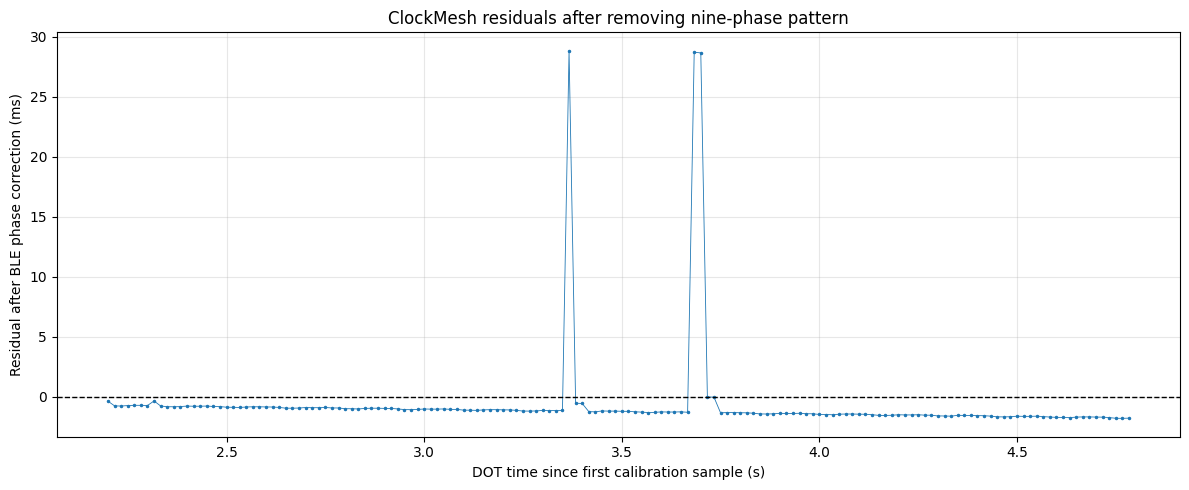

In [14]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    check["dot_elapsed_s"],
    check["remaining_ms"],
    ".-",
    markersize=3,
    linewidth=0.6
)

ax.axhline(0, color="black", linestyle="--", linewidth=1)

ax.set_xlabel("DOT time since first calibration sample (s)")
ax.set_ylabel("Residual after BLE phase correction (ms)")
ax.set_title("ClockMesh residuals after removing nine-phase pattern")

ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [15]:
x = normal_check["dot_elapsed_s"].to_numpy()
y = normal_check["remaining_ms"].to_numpy()

# Fit: residual_ms = slope * elapsed_s + intercept
slope, intercept = np.polyfit(x, y, 1)

print(f"Residual drift: {slope:.6f} ms/s")
print(f"Equivalent rate difference: {slope * 1000:.1f} ppm")
print(f"Intercept: {intercept:.3f} ms")

Residual drift: -0.406736 ms/s
Equivalent rate difference: -406.7 ppm
Intercept: 0.228 ms


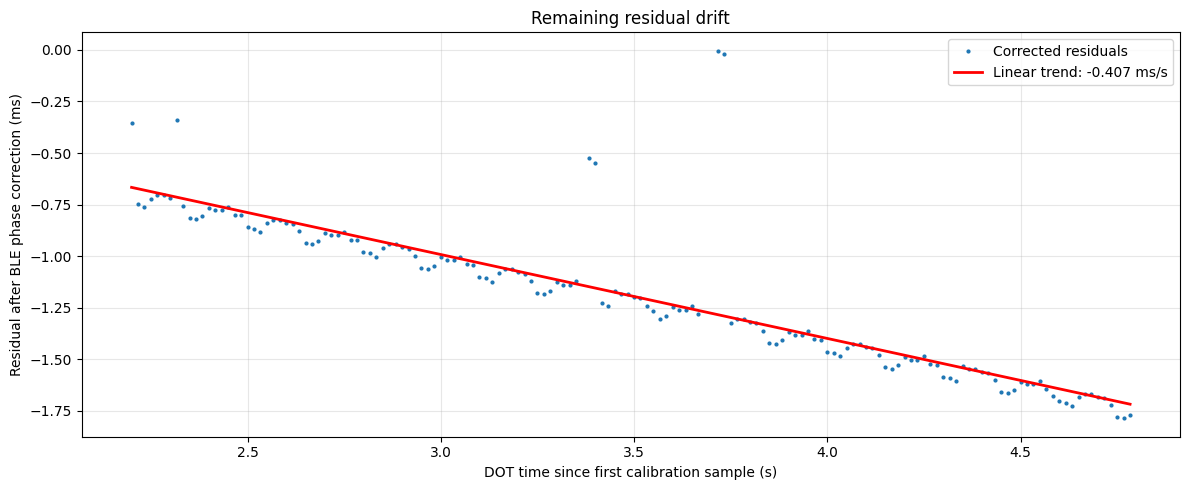

In [16]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(x, y, ".", markersize=4, label="Corrected residuals")

ax.plot(
    x,
    slope * x + intercept,
    "r-",
    linewidth=2,
    label=f"Linear trend: {slope:.3f} ms/s"
)

ax.set_xlabel("DOT time since first calibration sample (s)")
ax.set_ylabel("Residual after BLE phase correction (ms)")
ax.set_title("Remaining residual drift")
ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

In [17]:

# Confirm the accepted scale stayed constant.
print("Accepted scale range:")

print(
    normal_check["estimated_scale_ns_per_source_unit"]
    .agg(["min", "max"])
)

# Examine the latest candidate within our analysis window.
latest = plot_data.sort_values(
    "unwrapped_dot_timestamp_us"
).iloc[-1]

print("\nLatest tracking state:")
print(latest[[
    "dot_elapsed_s",
    "model_state",
    "estimated_scale_ns_per_source_unit",
    "candidate_scale_ns_per_source_unit",
    "retained_tracking_observation_count",
]])

print("\nResidual-derived scale estimate:")
print(f"{1000.3815645001883 + slope:.6f} ns/us")

Accepted scale range:
min    1000.381565
max    1000.381565
Name: estimated_scale_ns_per_source_unit, dtype: float64

Latest tracking state:
dot_elapsed_s                             4.783429
model_state                               tracking
estimated_scale_ns_per_source_unit     1000.381565
candidate_scale_ns_per_source_unit      1000.00889
retained_tracking_observation_count            166
Name: 566, dtype: object

Residual-derived scale estimate:
999.974828 ns/us
